In [1]:
from pathlib import Path
import pickle

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import Lasso, LinearRegression
from sklearn.metrics import root_mean_squared_error
from xgboost import XGBRegressor

In [2]:
data_path = Path("data/yellow_tripdata_2026-05.parquet")

if not data_path.exists():
    raise FileNotFoundError(f"Fichier introuvable : {data_path}")

data_path

PosixPath('data/yellow_tripdata_2026-05.parquet')

In [3]:
df = pd.read_parquet(data_path)
df.shape

(4090836, 20)

In [4]:
columns = [
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "PULocationID",
    "DOLocationID",
    "trip_distance",
]

df[columns].head()

,tpep_pickup_datetime,tpep_dropoff_datetime,PULocationID,DOLocationID,trip_distance
0,2026-05-01 00:04:59,2026-05-01 00:32:48,138,37,7.51
1,2026-05-01 00:37:05,2026-05-01 00:59:47,138,237,6.14
2,2026-05-01 00:34:05,2026-05-01 00:54:02,249,232,2.40
3,2026-05-01 00:55:07,2026-05-01 01:02:43,232,114,1.20
4,2026-05-01 00:44:13,2026-05-01 00:44:13,140,237,0.86


In [5]:
df["duration"] = (
    df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]
).dt.total_seconds() / 60

df["duration"].describe()

count    4.090836e+06
mean     1.877588e+01
std      2.671057e+01
min      0.000000e+00
25%      8.583333e+00
50%      1.448333e+01
75%      2.326667e+01
max      9.960150e+03
Name: duration, dtype: float64

In [6]:
df = df[df["duration"].between(1, 60)].copy()

categorical = ["PULocationID", "DOLocationID"]
numerical = ["trip_distance"]

df[categorical] = df[categorical].astype(str)
df["PU_DO"] = df["PULocationID"] + "_" + df["DOLocationID"]

df.shape

(3883752, 22)

In [7]:
sample_size = min(200_000, len(df))
df = df.sample(n=sample_size, random_state=42)
df = df.sort_values("tpep_pickup_datetime").reset_index(drop=True)

In [8]:
split_index = int(len(df) * 0.8)

df_train = df.iloc[:split_index].copy()
df_val = df.iloc[split_index:].copy()

len(df_train), len(df_val)

(160000, 40000)

In [9]:
features = ["PU_DO", "trip_distance"]

train_dicts = df_train[features].to_dict(orient="records")
val_dicts = df_val[features].to_dict(orient="records")

dv = DictVectorizer()
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

y_train = df_train["duration"].to_numpy()
y_val = df_val["duration"].to_numpy()

X_train.shape, X_val.shape

((160000, 12641), (40000, 12641))

In [10]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_val)
linear_rmse = root_mean_squared_error(y_val, linear_predictions)

linear_rmse

6.6551909673636604

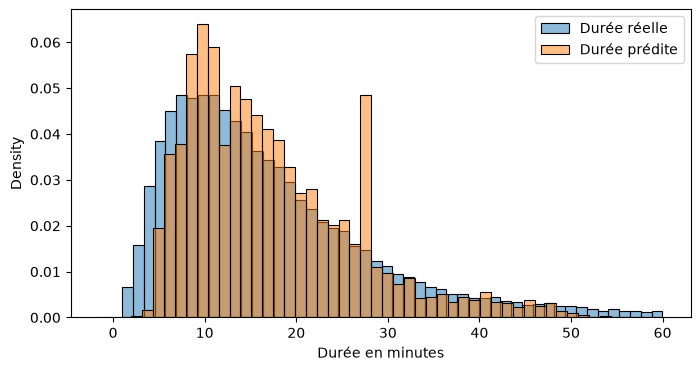

In [11]:
plt.figure(figsize=(8, 4))
sns.histplot(y_val, label="Durée réelle", stat="density", bins=50, alpha=0.5)
sns.histplot(
    linear_predictions,
    label="Durée prédite",
    stat="density",
    bins=50,
    alpha=0.5,
)

plt.xlabel("Durée en minutes")
plt.legend()
plt.show()

In [13]:
# Correction de compatibilité des indices
X_train = X_train.tocsc()
X_train.indices = X_train.indices.astype("int32")
X_train.indptr = X_train.indptr.astype("int32")

# Code du professeur
lasso_model = Lasso(alpha=0.01, max_iter=10_000)
lasso_model.fit(X_train, y_train)

lasso_predictions = lasso_model.predict(X_val)
lasso_rmse = root_mean_squared_error(y_val, lasso_predictions)

lasso_rmse

10.517043400486218

In [14]:
xgb_model = XGBRegressor(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1,
)

xgb_model.fit(X_train, y_train)

xgb_predictions = xgb_model.predict(X_val)
xgb_rmse = root_mean_squared_error(y_val, xgb_predictions)

xgb_rmse

6.471618951707119